In [12]:
!pip3 install numpy matplotlib

In [ ]:
import numpy as np
import math

In [8]:
def const(c):
    return lambda x: c

def exp_func(c):
    return lambda x: c - 0.6 * math.exp(-2 * x)

bounds = [
    (-4, const(0)),
    (-2, const(0.02)),
    (-1, const(0.05)),
    (0, const(0.075)),
    (0.5, exp_func(0.72)),
    (1, exp_func(0.755)),
    (1.5, exp_func(0.81)),
    (2, exp_func(0.85)),
    (3, exp_func(0.9)),
    (5, exp_func(0.945)),
    (None, exp_func(1))
]

effective_range = (-4, 5)

def F(x):
    for i in range(len(bounds) - 1):
        if x < bounds[i][0]:
            return bounds[i][1](x)
    return bounds[-1][1](x)

In [32]:
epsilon = 1e-8

# Ищем inf бинарным поиском, зная, что результат
# ограничен диапазоном [-4, 5]
def F_inverse(t):
    assert 0 <= t <= 1

    l, r = effective_range

    while r - l > epsilon:
        m = (r + l) / 2

        if F(m) < t:
            l = m
        else:
            r = m

    return r

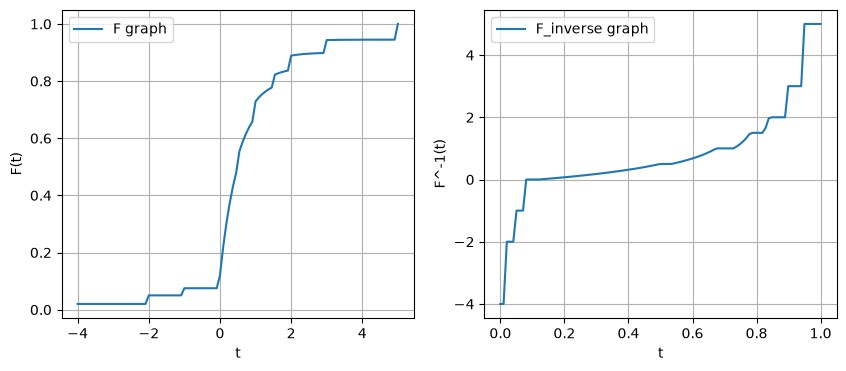

In [55]:
from matplotlib import pyplot as plt

N_DOTS = 100

F_x = np.linspace(*effective_range, N_DOTS)
F_y = list(map(F, F_x))

F_inverse_x = np.linspace(0, 1, N_DOTS)
F_inverse_y = list(map(F_inverse, F_inverse_x))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(F_x, F_y, label='F graph')
ax1.set_xlabel('t')
ax1.set_ylabel('F(t)')
ax1.legend()
ax1.grid(True)

ax2.plot(F_inverse_x, F_inverse_y, label='F_inverse graph')
ax2.set_xlabel('t')
ax2.set_ylabel('F^-1(t)')
ax2.legend()
ax2.grid(True)

plt.show()

In [ ]:
ROUND_DIGITS = 6

potential_discrete_points = list(map(lambda x: x[0], bounds[:-1]))
jumps = []

for pp in potential_discrete_points:
    jump = round(F(pp + epsilon) - F(pp - epsilon), ROUND_DIGITS)
    jumps.append((pp, jump))

print('Jumps:')

for coord, jump in jumps:
    print(f'P(x={coord}) = {jump}')


Jumps:
P(x=-4) = 0.02
P(x=-2) = 0.03
P(x=-1) = 0.025
P(x=0) = 0.045
P(x=0.5) = 0.035
P(x=1) = 0.055
P(x=1.5) = 0.04
P(x=2) = 0.05
P(x=3) = 0.045
P(x=5) = 0.055


In [ ]:
cumulative_discrete = 0

print('F_decsr = {')

print(f'  0, x < {jumps[0][0]}')

for i in range(len(jumps) - 1):
    cumulative_discrete = round(cumulative_discrete + jumps[i][1], ROUND_DIGITS)
    print(f'  {cumulative_discrete}, {jumps[i][0]} <= x < {jumps[i + 1][0]}')


cumulative_discrete = round(cumulative_discrete + jumps[-1][1], ROUND_DIGITS)
print(f'  {cumulative_discrete}, x >= {jumps[-1][0]}')

print('}')

F_decsr = {
  0, x < -4
  0.02, -4 <= x < -2
  0.05, -2 <= x < -1
  0.075, -1 <= x < 0
  0.12, 0 <= x < 0.5
  0.155, 0.5 <= x < 1
  0.21, 1 <= x < 1.5
  0.25, 1.5 <= x < 2
  0.3, 2 <= x < 3
  0.345, 3 <= x < 5
  0.4, x >= 5
}


In [ ]:
def F_descr(x):
    i = 0
    prob = 0
    while i < len(jumps) and x >= jumps[i][0]:
        prob += jumps[i][1]
        i += 1
    return prob

# нахаляву)
def F_cont(x):
    return F(x) - F_descr(x)

alpha = cumulative_discrete

def F_split(x):
    return alpha * F_descr(x) + (1 - alpha) * F_cont(x)

0.4

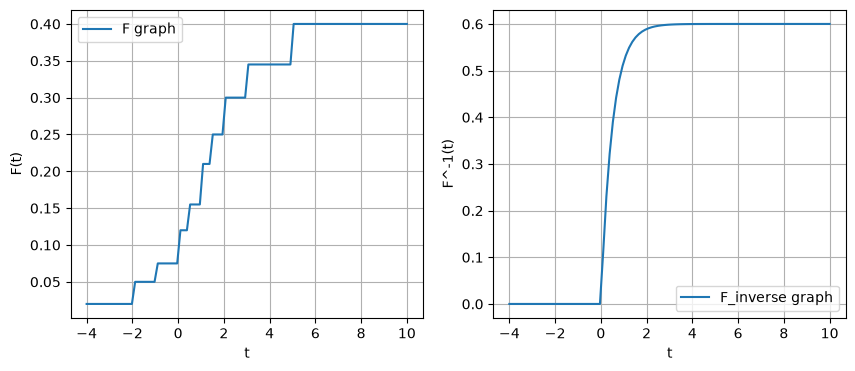

In [63]:
from matplotlib import pyplot as plt

N_DOTS = 100

F_x = np.linspace(effective_range[0], effective_range[1] + 5, N_DOTS)
F_y = list(map(F_descr, F_x))

F_inverse_x = np.linspace(effective_range[0], effective_range[1] + 5, N_DOTS)
F_inverse_y = list(map(F_cont, F_inverse_x))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(F_x, F_y, label='F graph')
ax1.set_xlabel('t')
ax1.set_ylabel('F(t)')
ax1.legend()
ax1.grid(True)

ax2.plot(F_inverse_x, F_inverse_y, label='F_inverse graph')
ax2.set_xlabel('t')
ax2.set_ylabel('F^-1(t)')
ax2.legend()
ax2.grid(True)

plt.show()

In [61]:
F_x

array([-4.        , -3.90909091, -3.81818182, -3.72727273, -3.63636364,
       -3.54545455, -3.45454545, -3.36363636, -3.27272727, -3.18181818,
       -3.09090909, -3.        , -2.90909091, -2.81818182, -2.72727273,
       -2.63636364, -2.54545455, -2.45454545, -2.36363636, -2.27272727,
       -2.18181818, -2.09090909, -2.        , -1.90909091, -1.81818182,
       -1.72727273, -1.63636364, -1.54545455, -1.45454545, -1.36363636,
       -1.27272727, -1.18181818, -1.09090909, -1.        , -0.90909091,
       -0.81818182, -0.72727273, -0.63636364, -0.54545455, -0.45454545,
       -0.36363636, -0.27272727, -0.18181818, -0.09090909,  0.        ,
        0.09090909,  0.18181818,  0.27272727,  0.36363636,  0.45454545,
        0.54545455,  0.63636364,  0.72727273,  0.81818182,  0.90909091,
        1.        ,  1.09090909,  1.18181818,  1.27272727,  1.36363636,
        1.45454545,  1.54545455,  1.63636364,  1.72727273,  1.81818182,
        1.90909091,  2.        ,  2.09090909,  2.18181818,  2.27

In [ ]:
def generate_random1():
    u = np.random.uniform(0, 1)
    return F_inverse(u)

def generate_random2():
    if np.random.uniform(0, 1) < alpha:
        # discrete
        return 0
    else:
        return 0


0.07155895233154297